# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

Направление: 38.04.05 «Бизнес-информатика», магистратура
Формат: интерактивный ноутбук Google Colab · до 100 баллов · срок сдачи — по графику курса

**Вариант 12 — Логистика: «Температурный режим перевозок: risk-календарь на две недели»**

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.

Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.

Нормализовать «грязные» поля (цены, остатки, зарплатные вилки, даты, технологии в тексте требований) регулярными выражениями.

Собрать единый pandas.DataFrame, провести разведочный анализ и построить корректные графики.

Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|------|-------------|
| Сбор | requests (+ urllib3.Retry), открытые REST API, кэш ответов на диске, паузы и ретраи |
| Разбор HTML | BeautifulSoup4 (CSS-селекторы), lxml (XPath) |
| Очистка | re — регулярные выражения |
| Анализ и графики | pandas, numpy, matplotlib, seaborn |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук со всеми выводами ячеек, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся ссылка на репозиторий. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

Файл → Сохранить копию на Диске. Работайте только в своей копии.

В ячейке «Шаг 1» задайте номер варианта (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.

Выполняйте ячейки строго сверху вниз. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».

Места, которые нужно дописать, помечены TODO. Пока шаг не выполнен, ячейка честно падает с NotImplementedError — это нормально.

Перед сдачей запустите ячейку самопроверки: она должна показать «Выполнено: 11 из 11».

### Три правила вежливого сбора данных

Пауза между запросами. REQUEST_PAUSE = 0.5 секунды — нижняя граница для учебной работы. Сервер, который вы «положите», принадлежит другим людям.

Кэш включён по умолчанию. Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите USE_CACHE или очистите папку кэша.

Никаких ключей в коде. Токены читаются функцией get_secret() из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. Выводы по аварийным данным не принимаются — повторите сбор, когда источник снова доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

API — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
```

```
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

- Эндпоинт — «ручка» сервиса: /vacancies, /works, /search/repositories.
- Параметры уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
- Заголовки описывают клиента. User-Agent с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.

Коды ответа — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать r.json() |
| 301 / 302 | адрес изменился | проверить итоговый r.url |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать Retry-After, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | page, per_page | GitHub, OpenAlex |
| Смещение и размер | offset, limit | «Работа в России» |
| Курсор | cursor, next | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем per_page, — данные закончились. Бесконечный while True без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

- пауза между запросами (time.sleep);
- повторные попытки с экспоненциальной задержкой — в работе это urllib3.Retry(backoff_factor=1.5): 1,5 с → 3 с → 6 с;
- уважение заголовков X-RateLimit-Remaining и Retry-After;
- кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть Secrets (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через userdata.get("MY_KEY"). В работе это обёрнуто в get_secret().

### Что изменилось к 2026 году (важно для выбора источника)

- hh.ru: с апреля 2026 публичный метод GET /vacancies отвечает 403 Forbidden на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал «Работа в России» (opendata.trudvsem.ru), данные Роструда, ключ не нужен.
- OpenAlex: с 13 февраля 2026 всем запросам нужен бесплатный api_key, параметр mailto и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы search дороже, чем filter, а получение объекта по идентификатору бесплатно. Отсюда практический приём: per-page=100 и фильтры вместо поиска.
- GitHub: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: источник — это не константа. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в DOM — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

|  | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | soup.select("article.product_pod p.price_color") | tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()') |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | el.get("title") | .../@title |
| Текст | el.get_text(" ", strip=True) | .../text() |
| Поиск по тексту | soup.find("th", string="UPC") | //th[text()="UPC"] |
| Движение «вверх» и «вбок» | el.parent, el.find_next_sibling() | оси: parent::, following-sibling::, ancestor:: |
| Условие по числу | средствами Python | [position() <= 3], [last()] |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

Когда что удобнее. CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

Цепляйтесь за смысл, а не за форму. div > div > div:nth-child(3) сломается при первом же редизайне; p.price_color переживёт его.

Проверяйте на нескольких страницах. Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.

Отсутствие элемента — норма. select_one() вернёт None; парсер должен записать None в поле, а не падать.

Сверяйте два способа. В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.

Динамические сайты. Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от "от 60 000 до 90 000 руб." к паре (60000, 90000).

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| \d, \w, \s | цифра, буква/цифра/подчёркивание, пробельный символ | \d{4} — год |
| +, *, ?, {n,m} | повторения | \d{1,3} |
| (?P<name>...) | именованная группа | (?P<min>\d+) → m.group("min") |
| (?:...) | группировка без захвата | (?:руб\.?|₽) |
| [...], [^...] | символьный класс и его отрицание | [£$€₽] |
| \b | граница слова | \bBI\b не совпадёт внутри BigData |
| ? после квантификатора | ленивый режим | <.+?> |
| re.I, re.S, re.X | флаги: регистр, . включая перевод строки, «читаемый» режим | |

Функции: re.search — первое совпадение, re.findall — все, re.sub — замена, re.compile — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | (?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?) | в 1 250,50 ₽ стоит неразрывный пробел \u00a0, а десятичный разделитель — запятая |
| Остаток | \((?P<n>\d+)\s*available\) | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | (?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))? | «по договорённости» → (None, None); одиночное число — это и нижняя, и верхняя граница |
| Дата | (?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4}) и \d{4}-\d{2}-\d{2} | в одном источнике встречаются оба формата |
| Технология в тексте | (?<![\w])(python|sql|power bi)(?![\w]) | без границ bi найдётся в «combined» |

### Чего делать не нужно

Разбирать HTML регулярками. Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.

Писать одно «универсальное» выражение на все случаи. Проще и надёжнее несколько маленьких функций с тестами.

Верить, что очистка прошла успешно. Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

robots.txt и пользовательское соглашение. Перед сбором смотрим https://сайт/robots.txt и раздел об использовании данных. Запрет в robots.txt — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.

Нагрузка. Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.

Персональные данные. Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.

Авторские права и лицензии. Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.

Прозрачность. В User-Agent указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны учебные витрины (books.toscrape.com, quotes.toscrape.com, webscraper.io/test-sites, scrapethissite.com), созданные специально для тренировки, и открытые государственные и научные данные. Навык переносится на коммерческие источники, а юридические риски — нет.

## Шаг 1. Окружение, параметры варианта и работа с ключами

Зачем мы это делаем. Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый User-Agent с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

- Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504)) — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
- polite_get() никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
- get_secret() ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [1]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 12              #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "student@mgpu.ru"  #@param {type:"string"}  # замените на свой e-mail
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()

CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.
    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta
    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta
    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta
    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.11.12 | requests 2.34.2 | bs4 4.15.0 | lxml 6.1.3 | pandas 3.0.6 | seaborn 0.13.2
Вариант: 12 | кэш: pw1_cache | пауза между запросами: 0.5 с


Как читать вывод. В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Если пауза меньше 0,5 с, увеличьте её: при сборе десятков страниц это разница между «данные собраны» и «IP временно заблокирован».

In [2]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
    {
        "id": 1,
        "area": "HR-аналитика",
        "task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
        "api": "trudvsem",
        "api_params": {
            "text": "инженер машинного обучения",
            "pages": 5,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "science_22",
            "pages": 3
        },
        "metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
    },
    {
        "id": 2,
        "area": "E-commerce",
        "task": "Ценовое позиционирование в нише деловой литературы",
        "api": "trudvsem",
        "api_params": {
            "text": "аналитик маркетплейсов",
            "pages": 4,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "business_35",
            "pages": 3
        },
        "metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
    },
    {
        "id": 3,
        "area": "Финтех",
        "task": "Валютный риск закупок: динамика USD и EUR за квартал",
        "api": "cbr",
        "api_params": {
            "currencies": [
                "USD",
                "EUR"
            ],
            "days": 90
        },
        "site": "books",
        "site_params": {
            "category": "travel_2",
            "pages": 2
        },
        "metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
    },
    {
        "id": 4,
        "area": "Мониторинг конкурентов",
        "task": "Сравнение ассортимента двух товарных категорий",
        "api": "github",
        "api_params": {
            "q": "price monitoring",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "books",
        "site_params": {
            "category": "fiction_10",
            "pages": 4
        },
        "metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
    },
    {
        "id": 5,
        "area": "Наука и инновации",
        "task": "Научная активность в сфере FinTech: динамика публикаций",
        "api": "openalex",
        "api_params": {
            "search": "fintech",
            "from_year": 2019,
            "per_page": 100,
            "pages": 2
        },
        "site": "quotes",
        "site_params": {
            "tag": "inspirational",
            "pages": 4
        },
        "metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
    },
    {
        "id": 6,
        "area": "Логистика",
        "task": "Погодные риски на складских хабах: планирование окон отгрузки",
        "api": "openmeteo",
        "api_params": {
            "cities": [
                "Москва",
                "Екатеринбург",
                "Новосибирск"
            ],
            "days": 14
        },
        "site": "books",
        "site_params": {
            "category": "history_32",
            "pages": 2
        },
        "metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
    },
    {
        "id": 7,
        "area": "HR-аналитика",
        "task": "Спрос на дата-инженеров и требования к стеку",
        "api": "trudvsem",
        "api_params": {
            "text": "инженер данных",
            "pages": 5,
            "per_page": 100
        },
        "site": "quotes",
        "site_params": {
            "tag": "life",
            "pages": 3
        },
        "metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
    },
    {
        "id": 8,
        "area": "E-commerce",
        "task": "Влияние рейтинга на цену: есть ли премия за качество",
        "api": "github",
        "api_params": {
            "q": "recommender system",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "books",
        "site_params": {
            "category": "romance_8",
            "pages": 4
        },
        "metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
    },
    {
        "id": 9,
        "area": "Финтех",
        "task": "Стоимость валютной корзины импортёра",
        "api": "cbr",
        "api_params": {
            "currencies": [
                "USD",
                "EUR",
                "CNY"
            ],
            "days": 120
        },
        "site": "webscraper",
        "site_params": {
            "section": "computers/laptops",
            "pages": 3
        },
        "metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
    },
    {
        "id": 10,
        "area": "Мониторинг конкурентов",
        "task": "Глубина ассортимента и «дыры» в наличии у конкурента",
        "api": "trudvsem",
        "api_params": {
            "text": "категорийный менеджер",
            "pages": 4,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "mystery_3",
            "pages": 4
        },
        "metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
    },
    {
        "id": 11,
        "area": "Наука и инновации",
        "task": "Публикационный ландшафт по теме «supply chain analytics»",
        "api": "openalex",
        "api_params": {
            "search": "supply chain analytics",
            "from_year": 2020,
            "per_page": 100,
            "pages": 2
        },
        "site": "scrapethissite",
        "site_params": {
            "section": "countries",
            "pages": 1
        },
        "metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
    },
    {
        "id": 12,
        "area": "Логистика",
        "task": "Температурный режим перевозок: risk-календарь на две недели",
        "api": "openmeteo",
        "api_params": {
            "cities": [
                "Санкт-Петербург",
                "Казань",
                "Краснодар"
            ],
            "days": 14
        },
        "site": "webscraper",
        "site_params": {
            "section": "computers/tablets",
            "pages": 3
        },
        "metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
    },
    {
        "id": 13,
        "area": "HR-аналитика",
        "task": "BI-аналитики: сколько стоит и что требуют работодатели",
        "api": "trudvsem",
        "api_params": {
            "text": "BI аналитик",
            "pages": 5,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "business_35",
            "pages": 3
        },
        "metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
    },
    {
        "id": 14,
        "area": "Технологические тренды",
        "task": "Экосистема инструментов парсинга: кто лидирует",
        "api": "github",
        "api_params": {
            "q": "web scraping",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "quotes",
        "site_params": {
            "tag": "books",
            "pages": 3
        },
        "metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
    },
    {
        "id": 15,
        "area": "E-commerce",
        "task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
        "api": "trudvsem",
        "api_params": {
            "text": "менеджер интернет-магазина",
            "pages": 4,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "childrens_11",
            "pages": 4
        },
        "metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
    },
    {
        "id": 16,
        "area": "Финтех",
        "task": "Курс юаня и импорт электроники: чувствительность цены",
        "api": "cbr",
        "api_params": {
            "currencies": [
                "CNY"
            ],
            "days": 180
        },
        "site": "webscraper",
        "site_params": {
            "section": "phones/touch",
            "pages": 2
        },
        "metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
    },
    {
        "id": 17,
        "area": "Наука и инновации",
        "task": "Исследования по «digital twin» в промышленности",
        "api": "openalex",
        "api_params": {
            "search": "digital twin manufacturing",
            "from_year": 2018,
            "per_page": 100,
            "pages": 2
        },
        "site": "books",
        "site_params": {
            "category": "science_22",
            "pages": 3
        },
        "metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
    },
    {
        "id": 18,
        "area": "Мониторинг конкурентов",
        "task": "Сравнение цен и «звёздности» ассортимента двух категорий",
        "api": "github",
        "api_params": {
            "q": "e-commerce analytics",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "books",
        "site_params": {
            "category": "food-and-drink_33",
            "pages": 3
        },
        "metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
    },
    {
        "id": 19,
        "area": "HR-аналитика",
        "task": "Логистические профессии: дефицит кадров по регионам",
        "api": "trudvsem",
        "api_params": {
            "text": "логист",
            "pages": 6,
            "per_page": 100
        },
        "site": "scrapethissite",
        "site_params": {
            "section": "countries",
            "pages": 1
        },
        "metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
    },
    {
        "id": 20,
        "area": "Логистика",
        "task": "Окна доставки в северных хабах на горизонте 16 дней",
        "api": "openmeteo",
        "api_params": {
            "cities": [
                "Мурманск",
                "Архангельск",
                "Якутск"
            ],
            "days": 16
        },
        "site": "books",
        "site_params": {
            "category": "travel_2",
            "pages": 2
        },
        "metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
    },
    {
        "id": 21,
        "area": "E-commerce",
        "task": "Автоматизация мониторинга: как часто меняется наличие товара",
        "api": "github",
        "api_params": {
            "q": "price tracker",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "books",
        "site_params": {
            "category": "sequential-art_5",
            "pages": 4
        },
        "metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
    },
    {
        "id": 22,
        "area": "Финтех",
        "task": "Волатильность рубля как фактор ценообразования",
        "api": "cbr",
        "api_params": {
            "currencies": [
                "USD",
                "EUR"
            ],
            "days": 365
        },
        "site": "books",
        "site_params": {
            "category": "business_35",
            "pages": 3
        },
        "metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
    },
    {
        "id": 23,
        "area": "HR-аналитика",
        "task": "Продуктовые аналитики: требования и вилки",
        "api": "trudvsem",
        "api_params": {
            "text": "продуктовый аналитик",
            "pages": 5,
            "per_page": 100
        },
        "site": "quotes",
        "site_params": {
            "tag": "humor",
            "pages": 3
        },
        "metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
    },
    {
        "id": 24,
        "area": "Технологические тренды",
        "task": "Инструменты работы с данными: Python-экосистема",
        "api": "github",
        "api_params": {
            "q": "pandas alternative dataframe",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "webscraper",
        "site_params": {
            "section": "computers/laptops",
            "pages": 3
        },
        "metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
    },
    {
        "id": 25,
        "area": "Наука и инновации",
        "task": "Публикации по «marketplace pricing»: кто задаёт повестку",
        "api": "openalex",
        "api_params": {
            "search": "marketplace pricing",
            "from_year": 2019,
            "per_page": 100,
            "pages": 2
        },
        "site": "books",
        "site_params": {
            "category": "business_35",
            "pages": 3
        },
        "metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
    },
    {
        "id": 26,
        "area": "Логистика",
        "task": "Планирование складских смен по погодным окнам",
        "api": "openmeteo",
        "api_params": {
            "cities": [
                "Ростов-на-Дону",
                "Самара",
                "Пермь"
            ],
            "days": 14
        },
        "site": "scrapethissite",
        "site_params": {
            "section": "hockey",
            "pages": 2
        },
        "metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
    },
    {
        "id": 27,
        "area": "Мониторинг конкурентов",
        "task": "Бенчмарк цен на технику: разброс внутри линейки",
        "api": "trudvsem",
        "api_params": {
            "text": "менеджер по закупкам",
            "pages": 4,
            "per_page": 100
        },
        "site": "webscraper",
        "site_params": {
            "section": "computers/laptops",
            "pages": 3
        },
        "metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
    },
    {
        "id": 28,
        "area": "E-commerce",
        "task": "Влияние глубины каталога на средний чек (гипотеза)",
        "api": "github",
        "api_params": {
            "q": "shopping cart analytics",
            "sort": "stars",
            "pages": 2,
            "per_page": 50
        },
        "site": "books",
        "site_params": {
            "category": "poetry_23",
            "pages": 4
        },
        "metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
    },
    {
        "id": 29,
        "area": "Финтех",
        "task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
        "api": "cbr",
        "api_params": {
            "currencies": [
                "USD",
                "EUR",
                "CNY"
            ],
            "days": 180
        },
        "site": "quotes",
        "site_params": {
            "tag": "life",
            "pages": 3
        },
        "metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
    },
    {
        "id": 30,
        "area": "E-commerce + HR (эталон преподавателя)",
        "task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
        "api": "trudvsem",
        "api_params": {
            "text": "аналитик данных",
            "pages": 3,
            "per_page": 100
        },
        "site": "books",
        "site_params": {
            "category": "business_35",
            "pages": 3
        },
        "metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
    }
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}
def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]
CFG = variant_config()

# ---- расширение выборки до минимумов методички (фиксируется в отчёте) -------------------------
# Методичка: «не менее 50 записей из API и не менее 40 карточек с сайта. Если на вашем запросе
# данных меньше — расширьте ключевое слово или глубину пагинации и зафиксируйте это в отчёте».
#   API : 3 города × 14 дней прогноза = 42 < 50  → добавляем 7 дней фактической погоды (past_days),
#         итого 3 × 21 = 63 записи;
#   сайт: в разделе computers/tablets 21 карточка и нет пагинации (страница 2 не существует) < 40
#         → добавляем соседний раздел computers/laptops; медианы цен планшетов считаем
#         только по планшетам, ноутбуки — для сравнения.
EXTENSIONS = {}
if CFG["id"] == 12:
    CFG["api_params"]["past_days"] = 7
    CFG["site_params"]["sections"] = ["computers/tablets", "computers/laptops"]
    EXTENSIONS = {
        "API": "добавлено past_days=7 (7 дней факта + 14 дней прогноза): 42 → 63 записи",
        "сайт": "к computers/tablets (21 карточка, без пагинации) добавлен computers/laptops",
    }
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))
print("\nРасширения выборки (зафиксированы в отчёте):")
for k, v in EXTENSIONS.items():
    print(f"  {k}: {v}")

Вариант 12 — Логистика
Бизнес-задача: Температурный режим перевозок: risk-календарь на две недели

Источник API : api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)
Параметры API: {'cities': ['Санкт-Петербург', 'Казань', 'Краснодар'], 'days': 14, 'past_days': 7}
Сайт парсинга: webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)
Параметры    : {'section': 'computers/tablets', 'pages': 3, 'sections': ['computers/tablets', 'computers/laptops']}

Метрики и визуализации:
  Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов

Расширения выборки (зафиксированы в отчёте):
  API: добавлено past_days=7 (7 дней факта + 14 дней прогноза): 42 → 63 записи
  сайт: к computers/tablets (21 карточка, без пагинации) добавлен computers/laptops


### Шаг 1.2. Право и этика: robots.txt и пользовательские соглашения источников варианта

Зачем мы это делаем. Раздел «Право и этика сбора данных» требует перед сбором посмотреть robots.txt и правила использования данных каждого источника. Делаем это кодом, чтобы проверка была воспроизводимой и попала в отчёт:

- webscraper.io — учебная витрина; на странице https://webscraper.io/test-sites владелец прямо пишет, что эти сайты предназначены для тренировки («test sites that you can use for training»). robots.txt запрещает только разделы product/, pagination/, scroll/ и load-more/ — наш раздел allinone разрешён;
- Open-Meteo — открытый API. robots.txt на домене api.open-meteo.com закрывает адрес для поисковых роботов (Disallow: /), поэтому для API действуют условия использования (https://open-meteo.com/en/terms): бесплатный API только для некоммерческих целей, не более 10 000 запросов в сутки, 5 000 в час и 600 в минуту, данные распространяются по лицензии CC BY 4.0 (обязательна ссылка на Open-Meteo). Мы делаем 3 запроса с паузой и кэшем — это в тысячи раз ниже лимита;
- персональные данные не собираются: в выборке только погода и карточки товаров.

In [3]:
#@title Шаг 1.2. Проверка robots.txt и условий использования { display-mode: "form" }
from urllib import robotparser

ROBOTS_CHECK = [
    # (robots.txt, адрес, который будем запрашивать)
    ("https://webscraper.io/robots.txt",
     "https://webscraper.io/test-sites/e-commerce/allinone/computers/tablets"),
    ("https://webscraper.io/robots.txt",
     "https://webscraper.io/test-sites/e-commerce/allinone/computers/laptops"),
    ("https://api.open-meteo.com/robots.txt", "https://api.open-meteo.com/v1/forecast"),
]
TERMS = {
    "webscraper.io": "учебные тестовые сайты для тренировки парсинга (webscraper.io/test-sites)",
    "api.open-meteo.com": ("условия open-meteo.com/en/terms: некоммерческое использование, "
                           "< 10 000 запросов в сутки, лицензия данных CC BY 4.0"),
}
robots_rows = []
for robots_url, target in ROBOTS_CHECK:
    txt, meta = polite_get(robots_url, expect="txt", use_cache=False)
    rp = robotparser.RobotFileParser()
    rp.parse((txt or "").splitlines())
    host = robots_url.split("/")[2]
    robots_rows.append({"адрес запроса": target.split("//")[1],
                        "robots.txt": "получен" if txt is not None else f"нет ({meta.get('error')})",
                        "разрешено для User-Agent": rp.can_fetch(USER_AGENT, target),
                        "правила использования": TERMS[host]})
ROBOTS_DF = pd.DataFrame(robots_rows)
display(ROBOTS_DF)

,адрес запроса,robots.txt,разрешено для User-Agent,правила использования
0,webscraper.io/test-sites/e-commerce/allinone/c...,получен,True,учебные тестовые сайты для тренировки парсинга...
1,webscraper.io/test-sites/e-commerce/allinone/c...,получен,True,учебные тестовые сайты для тренировки парсинга...
2,api.open-meteo.com/v1/forecast,получен,False,условия open-meteo.com/en/terms: некоммерческо...


Как читать вывод. Для страниц webscraper.io в колонке «разрешено» должно стоять True — значит, robots.txt не запрещает наш раздел. Для api.open-meteo.com стоит False: robots.txt закрывает домен от поисковых роботов, но это API с опубликованными условиями использования, и доступ к нему регулируется именно ими — мы их соблюдаем (некоммерческая учебная задача, 3 запроса, пауза, кэш, указание лицензии CC BY 4.0 в выводах). Если для страницы сайта появится False — сбор с неё не ведём.

## Шаг 2. Сбор данных через открытый API

Зачем мы это делаем. API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

- остановка цикла, когда страница вернула меньше записей, чем запрошено;
- обращение к вложенным полям только через .get() — в открытых данных заполнены не все поля;
- печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

В варианте 12 источник — Open-Meteo: один запрос на город возвращает весь период сразу, поэтому роль «страницы» играет город, а остановка цикла — пустой ответ или ошибка запроса.

In [4]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}


# ------------------------------------------------------------------ TODO 2.1
def fetch_api(cfg):
    """Сбор суточной погоды Open-Meteo по городам варианта.

    Один запрос на город: 'past_days' дней факта + 'days' дней прогноза.
    Запрос идёт через polite_get() (ретраи, пауза, кэш); при ошибке город пропускается.
    """
    p = cfg["api_params"]
    days, past_days = p["days"], p.get("past_days", 0)
    records = []
    for i, city in enumerate(p["cities"], start=1):
        lat, lon = CITY_COORDS[city]
        params = {"latitude": lat, "longitude": lon,
                  "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
                  "timezone": "auto", "forecast_days": days, "past_days": past_days}
        data, meta = polite_get(OPENMETEO_URL, params=params)
        daily = (data or {}).get("daily") or {}
        n = len(daily.get("time") or [])
        if data is None or n == 0:      # ошибка или пустой ответ — прекращаем обработку города
            print(f"  [{i}/{len(p['cities'])}] {city}: нет данных — {meta.get('error')}")
            continue
        for k in range(n):
            records.append({
                "city": city,
                "date": daily["time"][k],
                "kind": "факт" if k < past_days else "прогноз",
                "temperature_2m_max": (daily.get("temperature_2m_max") or [None] * n)[k],
                "temperature_2m_min": (daily.get("temperature_2m_min") or [None] * n)[k],
                "precipitation_sum": (daily.get("precipitation_sum") or [None] * n)[k],
            })
        src = "кэш" if meta.get("from_cache") else f"сеть, HTTP {meta.get('status')}"
        print(f"  [{i}/{len(p['cities'])}] {city}: получено дней: {n} ({src})")
    return records


# ------------------------------------------------------------------ TODO 2.2
def normalize_api(raw, source):
    """Плоский список словарей с понятными именами колонок; вложенные поля — через .get()."""
    rows = []
    for r in raw:
        rows.append({
            "city": r.get("city"),
            "date_text": r.get("date"),
            "kind": r.get("kind"),
            "t_max": r.get("temperature_2m_max"),
            "t_min": r.get("temperature_2m_min"),
            "precip_mm": r.get("precipitation_sum"),
            "source": source,
        })
    return rows


raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
if df_api.empty:
    API_SOURCE = "synthetic"
    print("⚠ Источник недоступен: данных нет, выводы делать нельзя — повторите сбор позже.")
COLLECTED_AT = datetime.now().strftime("%d.%m.%Y %H:%M")
print(f"Собрано записей: {len(df_api)} (дата сбора: {COLLECTED_AT})")
if len(df_api):
    print("По видам:", df_api["kind"].value_counts().to_dict(),
          "| период:", df_api["date_text"].min(), "—", df_api["date_text"].max())
display(df_api.head())

  [1/3] Санкт-Петербург: получено дней: 21 (сеть, HTTP 200)


  [2/3] Казань: получено дней: 21 (сеть, HTTP 200)


  [3/3] Краснодар: получено дней: 21 (сеть, HTTP 200)
Ключи первой записи: ['city', 'date', 'kind', 'precipitation_sum', 'temperature_2m_max', 'temperature_2m_min']
Собрано записей: 63 (дата сбора: 06.10.2026 21:49)
По видам: {'прогноз': 42, 'факт': 21} | период: 2026-09-29 — 2026-10-19


,city,date_text,kind,t_max,t_min,precip_mm,source
0,Санкт-Петербург,2026-09-29,факт,13.6,8.9,0.0,openmeteo
1,Санкт-Петербург,2026-09-30,факт,14.8,10.2,0.0,openmeteo
2,Санкт-Петербург,2026-10-01,факт,15.1,8.6,0.0,openmeteo
3,Санкт-Петербург,2026-10-02,факт,14.2,9.8,0.0,openmeteo
4,Санкт-Петербург,2026-10-03,факт,13.6,10.0,0.0,openmeteo


Как читать вывод. Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак из кэша: при повторном запуске сеть не используется, поэтому для свежих данных выключайте USE_CACHE.

Если в выводе появилось предупреждение об аварийном режиме, значит источник недоступен: пайплайн продолжит работу на синтетических данных, но выводы по ним недопустимы.

Для варианта 12 ожидается по 21 дню на каждый из трёх городов: 7 дней факта и 14 дней прогноза, всего 63 записи (не ниже минимума 50).

## Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

Зачем мы это делаем. Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это контроль качества: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию SITES: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

Раздел allinone учебной витрины webscraper.io статический: все карточки раздела уже есть в HTML первой страницы, подгрузки через JavaScript (XHR) нет, поэтому обращаться к скрытому API не нужно. Пагинации у allinone тоже нет — вторая страница не существует.

In [5]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
# Конфигурации сайтов даны частично: селекторы своего сайта проверьте сами
# (в браузере: правый клик по элементу → «Просмотреть код»).
SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
    # TODO 3.0 (только для вариантов с webscraper / scrapethissite):
    # конфигурация учебного каталога webscraper.io (вариант 12)
    "webscraper": {
        # у allinone нет пагинации: все карточки раздела на одной странице, страницы 2 нет
        "page_url": lambda p, section="computers/tablets", **kw: (
            f"https://webscraper.io/test-sites/e-commerce/allinone/{section}" if p == 1 else None),
        "item_css": "div.thumbnail",
        "fields_css": {"title": ("a.title", "title"), "price_text": ("h4.price span", "text"),
                       "description": ("p.description", "text"),
                       "reviews_text": ("p.review-count", "text"),
                       "rating_text": ("div.ratings p[data-rating]", "data-rating"),
                       "url": ("a.title", "href")},
        "item_xpath": '//div[contains(@class, "thumbnail")]',
        "fields_xpath": {"title": './/a[contains(@class, "title")]/@title',
                         "price_text": './/h4[contains(@class, "price")]/span/text()',
                         "description": './/p[contains(@class, "description")]/text()',
                         "reviews_text": './/p[contains(@class, "review-count")]//text()',
                         "rating_text": './/div[contains(@class, "ratings")]/p[@data-rating]/@data-rating',
                         "url": './/a[contains(@class, "title")]/@href'},
    },
}


# ------------------------------------------------------------------ TODO 3.1
def parse_with_bs4(html, site):
    """Разбор карточек через BeautifulSoup и CSS-селекторы из SITES[site]."""
    cfg = SITES[site]
    soup = BeautifulSoup(html, "lxml")
    rows = []
    for card in soup.select(cfg["item_css"]):
        row = {}
        for field, (selector, what) in cfg["fields_css"].items():
            el = card.select_one(selector)
            if el is None:                       # нет элемента — пишем None, а не падаем
                row[field] = None
            elif what == "text":
                row[field] = el.get_text(" ", strip=True) or None
            elif what == "class":
                row[field] = " ".join(el.get("class", []))
            else:
                row[field] = el.get(what)
        rows.append(row)
    return rows


# ------------------------------------------------------------------ TODO 3.2
def parse_with_xpath(html, site):
    """Тот же разбор через lxml и XPath; из списка результатов берём первый непустой."""
    cfg = SITES[site]
    tree = lxml_html.fromstring(html)
    rows = []
    for node in tree.xpath(cfg["item_xpath"]):
        row = {}
        for field, expr in cfg["fields_xpath"].items():
            values = [str(v).strip() for v in node.xpath(expr) if str(v).strip()]
            if expr.endswith("//text()"):        # текст из вложенных узлов склеиваем, как get_text()
                row[field] = " ".join(values) or None
            else:
                row[field] = values[0] if values else None
        rows.append(row)
    return rows


# ------------------------------------------------------------------ TODO 3.3
def collect_site(site, pages=3, use_cache=None, **site_params):
    """Обход разделов и страниц; каждая страница разбирается двумя способами.

    Возвращает (rows_bs4, rows_xpath). Ошибка загрузки страницы не роняет сбор:
    страница пропускается, а в лог пишется причина.
    """
    cfg = SITES[site]
    sections = site_params.get("sections") or [site_params.get("section")]
    rows_bs4, rows_xpath = [], []
    for section in sections:
        for p in range(1, pages + 1):
            url = cfg["page_url"](p, **{**site_params, "section": section})
            if url is None:
                print(f"  {section}: страницы {p} нет (раздел без пагинации) — обход раздела завершён")
                break
            html, meta = polite_get(url, expect="html", use_cache=use_cache)
            if html is None:
                print(f"  {section}, стр. {p}: ошибка загрузки — {meta.get('error')}")
                break
            b, x = parse_with_bs4(html, site), parse_with_xpath(html, site)
            for r in b + x:
                r["category"] = section.split("/")[-1]
            rows_bs4 += b
            rows_xpath += x
            src = "кэш" if meta.get("from_cache") else f"HTTP {meta.get('status')}"
            print(f"  {section}, стр. {p}: карточек: {len(b)} ({src})")
            if not b:
                break
    return rows_bs4, rows_xpath


rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]
titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")
display(df_web.head())
fields = [f for f in SITES[CFG["site"]]["fields_css"]]
full_same = sum(1 for a, b in zip(rows_bs4, rows_xpath) if all(a.get(f) == b.get(f) for f in fields))
print(f"Полное совпадение всех полей ({', '.join(fields)}): {full_same} из {len(rows_bs4)}")
print("Карточек по разделам:", df_web["category"].value_counts().to_dict() if len(df_web) else {})

  computers/tablets, стр. 1: карточек: 21 (HTTP 200)
  computers/tablets: страницы 2 нет (раздел без пагинации) — обход раздела завершён


  computers/laptops, стр. 1: карточек: 117 (HTTP 200)
  computers/laptops: страницы 2 нет (раздел без пагинации) — обход раздела завершён
Карточек: 138 | совпадение BS4 и XPath: 138 из 138


,title,price_text,description,reviews_text,rating_text,url,category
0,Lenovo IdeaTab,$69.99,"7"" screen, Android",7 reviews,3,/test-sites/e-commerce/allinone/product/10,tablets
1,IdeaTab A3500L,$88.99,"Black, 7"" IPS, Quad-Core 1.2GHz, 8GB, Android 4.2",7 reviews,4,/test-sites/e-commerce/allinone/product/15,tablets
2,Acer Iconia,$96.99,"7"" screen, Android, 16GB",7 reviews,1,/test-sites/e-commerce/allinone/product/11,tablets
3,Galaxy Tab 3,$97.99,"7"", 8GB, Wi-Fi, Android 4.2, White",2 reviews,2,/test-sites/e-commerce/allinone/product/18,tablets
4,Iconia B1-730HD,$99.99,"Black, 7"", 1.6GHz Dual-Core, 8GB, Android 4.4",1 reviews,3,/test-sites/e-commerce/allinone/product/27,tablets


Полное совпадение всех полей (title, price_text, description, reviews_text, rating_text, url): 138 из 138
Карточек по разделам: {'laptops': 117, 'tablets': 21}


Как читать вывод. Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Проверьте также, что число карточек соответствует ожидаемому (на учебной витрине — 20 на страницу) и что в таблице нет колонок, целиком заполненных None: пустая колонка — это почти всегда устаревший селектор, а не отсутствие данных на сайте.

В варианте 12 сверяются не только названия, но и все шесть полей карточки. Ожидается 21 планшет и 117 ноутбуков — всего 138 карточек (не ниже минимума 40); в каталоге allinone все карточки раздела на одной странице.

## Шаг 4. Очистка и нормализация регулярными выражениями

Зачем мы это делаем. «£47.82», «In stock (22 available)», «star-rating Three», «от 60 000 до 90 000 руб.» — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и тесты к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [6]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "   "     # неразрывные пробелы: '1 250 ₽' почти всегда содержит именно их

# ------------------------------------------------------------------ TODO 4.1–4.5
RE_PRICE = re.compile(
    r"(?P<num>\d{1,3}(?:[ ,   ]\d{3})+(?:[.,]\d{1,2})?"   # с разделителем тысяч
    r"|\d+(?:[.,]\d{1,2})?)")                                            # без разделителя: $1399


def parse_price(text):
    r"""'£51.77' → 51.77 | '1 250,50 ₽' → 1250.5 | '$1399' → 1399.0 | 'по договорённости' → None
       Вторая ветка выражения нужна для цен без разделителя тысяч: без неё '$1399'
       распознавалось бы как 139."""
    m = RE_PRICE.search(str(text or ""))
    if not m:
        return None
    num = re.sub(f"[ {NBSP}]", "", m.group("num"))
    if "," in num and "." in num:            # 1,399.00 — запятая разделяет тысячи
        num = num.replace(",", "")
    elif re.search(r",\d{3}$", num):        # 1,399 — тоже тысячи
        num = num.replace(",", "")
    return float(num.replace(",", "."))


RE_STOCK = re.compile(r"\((?P<n>\d+)\s*available\)", re.I)


def parse_stock(text):
    """'In stock (22 available)' → 22 | 'Out of stock' → 0"""
    s = str(text or "")
    if re.search(r"out\s+of\s+stock", s, re.I):
        return 0
    m = RE_STOCK.search(s)
    return int(m.group("n")) if m else None


RATING_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}


def parse_rating(class_text):
    """'star-rating Three' → 3 (слова One…Five); у webscraper рейтинг числом: '4' → 4"""
    s = str(class_text or "")
    m = re.search(r"\b(one|two|three|four|five)\b", s, re.I)
    if m:
        return RATING_WORDS[m.group(1).lower()]
    m = re.search(r"\b([1-5])\b", s)
    return int(m.group(1)) if m else None


def parse_reviews(text):
    """'14 reviews' → 14 (число отзывов в карточке webscraper)"""
    m = re.search(r"(?P<n>\d+)\s*reviews?", str(text or ""), re.I)
    return int(m.group("n")) if m else None


RE_SALARY = re.compile(r"(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?", re.I)


def parse_salary(text):
    """'от 60 000 до 90 000 руб.' → (60000.0, 90000.0); 'по договорённости' → (None, None)"""
    s = re.sub(f"[{NBSP}]", " ", str(text or ""))
    to_num = lambda g: float(re.sub(r"\s", "", g)) if g and g.strip() else None
    for m in RE_SALARY.finditer(s):
        lo, hi = to_num(m.group("min")), to_num(m.group("max"))
        if lo is not None or hi is not None:
            return lo, hi
    m = re.search(r"\d[\d\s]*\d|\d", s)            # одиночное число — и нижняя, и верхняя граница
    if m:
        v = to_num(m.group(0))
        return v, v
    return None, None


def extract_skills(text):
    """Найдите в тексте требований технологии из списка SKILLS.
       Границы слова обязательны, иначе 'BI' найдётся внутри 'BigData'.
       Длинные названия ищем первыми и «вырезаем», чтобы 'power bi' не дал лишний 'bi'."""
    s = str(text or "").lower()
    found = []
    for skill in sorted(SKILLS, key=len, reverse=True):
        pattern = r"(?<![\w])" + re.escape(skill) + r"(?![\w])"
        if re.search(pattern, s):
            found.append(skill)
            s = re.sub(pattern, " ", s)
    return sorted(found)


SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]


def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


RE_DATE_RU = re.compile(r"(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})")
RE_DATE_ISO = re.compile(r"(?P<y>\d{4})-(?P<m>\d{2})-(?P<d>\d{2})")


def parse_date(text):
    """'2026-03-15' и '15.03.2026' → pd.Timestamp"""
    s = str(text or "")
    m = RE_DATE_ISO.search(s) or RE_DATE_RU.search(s)
    if not m:
        return None
    return pd.Timestamp(int(m.group("y")), int(m.group("m")), int(m.group("d")))


# ------------------------------------------------------------------ автотесты регулярок
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
    # дополнительные кейсы варианта 12 — форматы, которые реально встречаются на webscraper.io
    (parse_price, "$1399", 1399.0), (parse_price, "$1,399.00", 1399.0),
    (parse_rating, "4", 4), (parse_reviews, "14 reviews", 14),
    (parse_date, "2026-10-06", pd.Timestamp("2026-10-06")),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print(f"Регулярные выражения прошли проверку: {len(CASES)} из {len(CASES)} кейсов")

# ------------------------------------------------------------------ TODO 4.7: примените к данным
df_web["price"] = df_web["price_text"].map(parse_price)
df_web["rating"] = df_web["rating_text"].map(parse_rating)
df_web["reviews"] = df_web["reviews_text"].map(parse_reviews)
df_web["description"] = df_web["description"].map(normalize_ws)
df_web["url"] = "https://webscraper.io" + df_web["url"].fillna("")

df_api["date"] = df_api["date_text"].map(parse_date)
for col in ["t_max", "t_min", "precip_mm"]:
    df_api[col] = pd.to_numeric(df_api[col], errors="coerce")
df_api["is_frost"] = df_api["t_min"] < 0          # признак заморозка: минимум суток ниже 0 °C

quality = pd.DataFrame([
    ("сайт", "price", df_web["price"].notna().mean()),
    ("сайт", "rating", df_web["rating"].notna().mean()),
    ("сайт", "reviews", df_web["reviews"].notna().mean()),
    ("API", "date", df_api["date"].notna().mean()),
    ("API", "t_min", df_api["t_min"].notna().mean()),
    ("API", "t_max", df_api["t_max"].notna().mean()),
], columns=["источник", "поле", "доля распознанных"])
quality["доля распознанных"] = (quality["доля распознанных"] * 100).round(1).astype(str) + " %"
display(quality)
print("Типы колонок сайта:", df_web[["price", "rating", "reviews"]].dtypes.astype(str).to_dict())
print(f"Цены: min ${df_web['price'].min():.2f}, max ${df_web['price'].max():.2f}")

Регулярные выражения прошли проверку: 15 из 15 кейсов


,источник,поле,доля распознанных
0,сайт,price,100.0 %
1,сайт,rating,100.0 %
2,сайт,reviews,100.0 %
3,API,date,100.0 %
4,API,t_min,100.0 %
5,API,t_max,100.0 %


Типы колонок сайта: {'price': 'float64', 'rating': 'int64', 'reviews': 'int64'}
Цены: min $69.99, max $1799.00


Как читать вывод. Сначала блок проверки регулярных выражений: пока он не показывает «все ок», данные трогать рано. Затем таблица качества очистки — доля распознанных значений по каждому источнику. Ориентир: не ниже 80 %. Если ниже, ищите формат, который выражение не покрывает (обычно это неразрывный пробел, диапазон «от … до …» или валюта, записанная словом). Помните: строки с нераспознанной ценой не исчезают — они превращаются в пропуски и молча уменьшают выборку.

Отдельно проверьте строку с минимальной и максимальной ценой: на webscraper.io цены ноутбуков доходят до четырёхзначных без разделителя тысяч («$1399»). Если максимум меньше 1 000 долларов, выражение обрезает цену — это та самая ошибка, которую ловит кейс «$1399» в автотестах.

## Шаг 5. Разведочный анализ и визуализация

Зачем мы это делаем. Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в pandas, а рисуем уже маленькие итоговые таблицы.

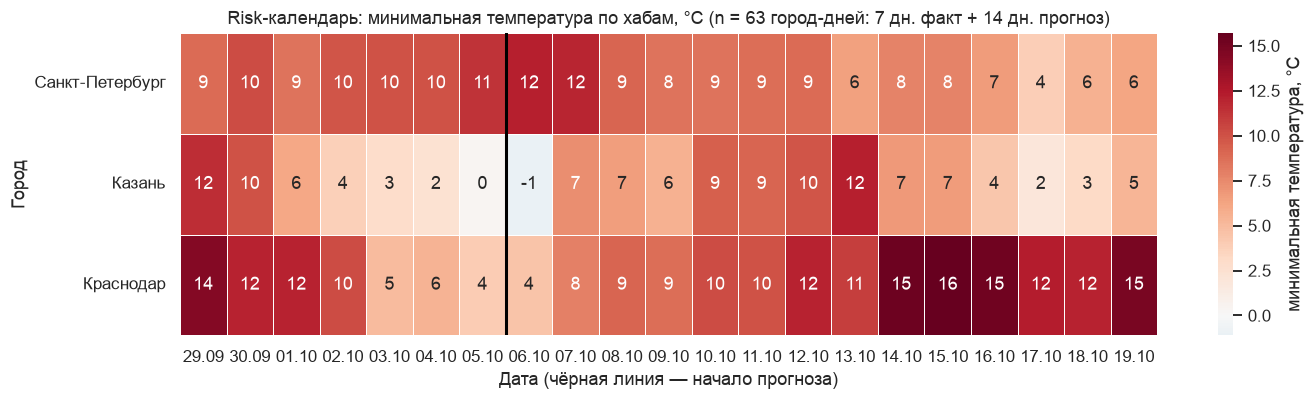

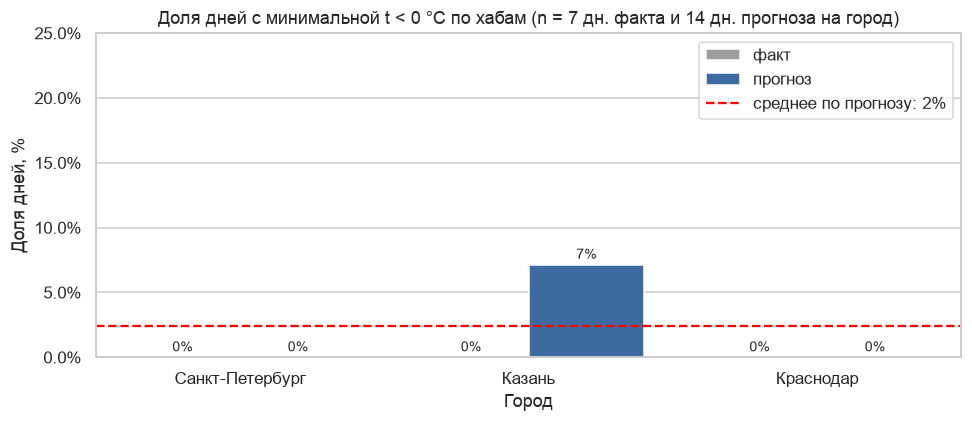

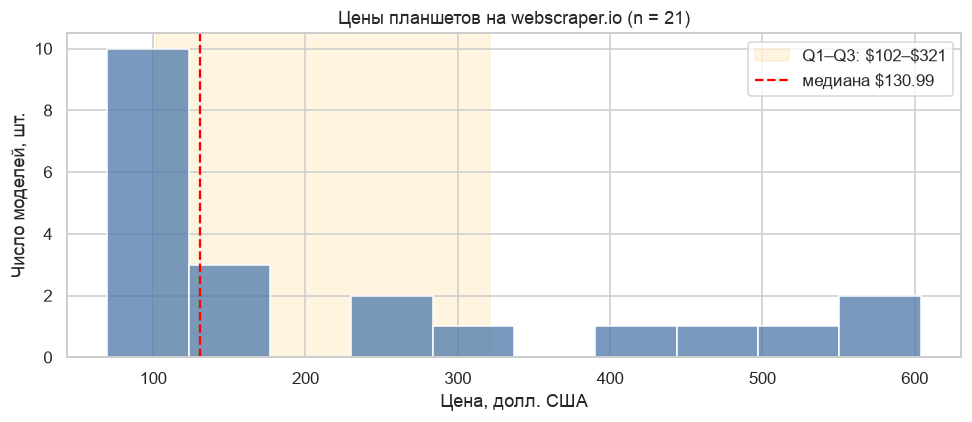

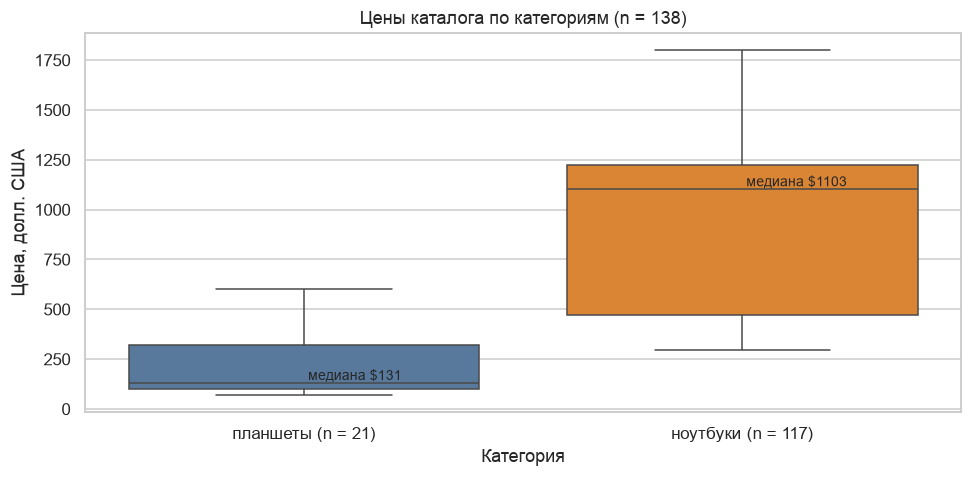

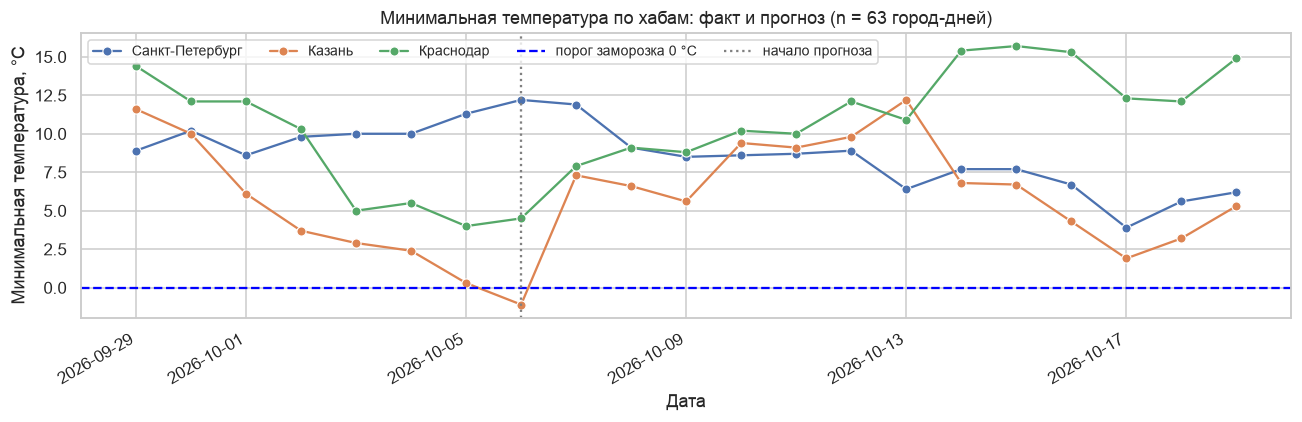

In [7]:
#@title Шаг 5. Разведочный анализ и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 5.1
# Пять графиков по метрикам варианта 12: heatmap «город — день», доля дней с t < 0 °C,
# цены планшетов (медиана), планшеты против ноутбуков, динамика минимальной температуры.
from matplotlib.ticker import PercentFormatter

CITIES = CFG["api_params"]["cities"]
FROST_T = 0.0                                   # порог заморозка из варианта, °C
n_days = df_api.groupby("city").size().max()
past = CFG["api_params"].get("past_days", 0)
forecast_start = df_api.loc[df_api["kind"] == "прогноз", "date"].min()

# 1. Heatmap «город — день»
heat = df_api.pivot(index="city", columns="date", values="t_min").reindex(CITIES)
heat = heat[sorted(heat.columns)]                 # столбцы строго по датам
heat.columns = [d.strftime("%d.%m") for d in heat.columns]
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu_r", center=FROST_T, linewidths=.5,
            cbar_kws={"label": "минимальная температура, °C"}, ax=ax)
ax.axvline(past, color="black", lw=2)             # граница факт | прогноз
ax.set_title(f"Risk-календарь: минимальная температура по хабам, °C "
             f"(n = {len(df_api)} город-дней: {past} дн. факт + {n_days - past} дн. прогноз)")
ax.set_xlabel("Дата (чёрная линия — начало прогноза)")
ax.set_ylabel("Город")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

# 2. Доля дней с t < 0 °C по хабам: факт и прогноз
frost = (df_api.groupby(["city", "kind"])["is_frost"].agg(["mean", "size"]).reset_index()
         .rename(columns={"mean": "share", "size": "n"}))
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=frost, x="city", y="share", hue="kind", order=CITIES,
            hue_order=["факт", "прогноз"], palette=["#9e9e9e", "#2b6cb0"], ax=ax)
overall = df_api.loc[df_api["kind"] == "прогноз", "is_frost"].mean()
ax.axhline(overall, color="red", ls="--", label=f"среднее по прогнозу: {overall:.0%}")
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0%}" for v in cont.datavalues], fontsize=9, padding=2)
ax.set_ylim(0, max(0.25, frost["share"].max() * 1.3))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title(f"Доля дней с минимальной t < 0 °C по хабам "
             f"(n = {past} дн. факта и {n_days - past} дн. прогноза на город)")
ax.set_xlabel("Город")
ax.set_ylabel("Доля дней, %")
ax.legend(title="")
plt.tight_layout()
plt.show()

# 3. Цены планшетов: распределение, медиана и квартили
tab = df_web.loc[df_web["category"] == "tablets", "price"].dropna()
q1, med, q3 = tab.quantile([.25, .5, .75])
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(tab, bins=10, color="#4c78a8", ax=ax)
ax.axvspan(q1, q3, color="orange", alpha=.12, zorder=0, label=f"Q1–Q3: \\${q1:.0f}–\\${q3:.0f}")
ax.axvline(med, color="red", ls="--", label=f"медиана \\${med:.2f}")
ax.set_title(f"Цены планшетов на webscraper.io (n = {len(tab)})")
ax.set_xlabel("Цена, долл. США")
ax.set_ylabel("Число моделей, шт.")
ax.legend()
plt.tight_layout()
plt.show()

# 4. Планшеты против ноутбуков: медианы и разброс
order = ["tablets", "laptops"]
labels = {"tablets": "планшеты", "laptops": "ноутбуки"}
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_web, x="category", y="price", order=order, hue="category", hue_order=order,
            palette=["#4c78a8", "#f58518"], legend=False, ax=ax)
meds = df_web.groupby("category")["price"].median()
cnt = df_web.groupby("category")["price"].size()
for i, c in enumerate(order):
    ax.text(i, meds[c], f" медиана \\${meds[c]:.0f}", va="bottom", ha="left", fontsize=9)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{labels[c]} (n = {cnt[c]})" for c in order])
ax.set_title(f"Цены каталога по категориям (n = {len(df_web)})")
ax.set_xlabel("Категория")
ax.set_ylabel("Цена, долл. США")
plt.tight_layout()
plt.show()

# 5. Динамика минимальной температуры по хабам
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=df_api, x="date", y="t_min", hue="city", hue_order=CITIES, marker="o", ax=ax)
ax.axhline(FROST_T, color="blue", ls="--", label="порог заморозка 0 °C")
ax.axvline(forecast_start, color="grey", ls=":", label="начало прогноза")
ax.set_title(f"Минимальная температура по хабам: факт и прогноз (n = {len(df_api)} город-дней)")
ax.set_xlabel("Дата")
ax.set_ylabel("Минимальная температура, °C")
ax.legend(title="", ncol=5, fontsize=9, loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Как читать вывод. На гистограмме цен смотрите не на среднее, а на форму: длинный правый хвост означает, что несколько дорогих позиций тянут среднее вверх, и для отчёта корректнее медиана. На графике цен по рейтингу обращайте внимание на подписи n=: медиана по трём товарам — это не закономерность. На распределении остатков важна доля позиций в наличии: это прямой индикатор качества управления запасами у конкурента. На боксплоте зарплат сравнивайте медианы и ширину коробок: широкая коробка означает, что в одной и той же роли рынок платит очень по-разному, и нанимать придётся точечно.

Для варианта 12: на heatmap синие клетки — дни с минимальной температурой ниже 0 °C, чёрная линия отделяет факт от прогноза; на столбчатой диаграмме сравнивайте доли морозных дней между хабами; на боксплоте — насколько планшеты дешевле ноутбуков и как широк их ценовой разброс.

## Шаг 6. Выводы и управленческие рекомендации

Зачем мы это делаем. Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [8]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default


tablets = df_web[df_web["category"] == "tablets"]
laptops = df_web[df_web["category"] == "laptops"]
fc = df_api[df_api["kind"] == "прогноз"]
frost_fc = fc.groupby("city")["is_frost"].sum().reindex(CITIES).astype(int)
coldest = fc.loc[fc["t_min"].idxmin()] if len(fc) else None

metrics = {
    "товаров собрано": len(df_web),
    "из них планшетов / ноутбуков": f"{len(tablets)} / {len(laptops)}",
    "медианная цена планшетов, $": safe(tablets["price"], lambda s: round(s.median(), 2)),
    "Q1 – Q3 цен планшетов, $": safe(tablets["price"], lambda s: f"{s.quantile(.25):.2f} – {s.quantile(.75):.2f}"),
    "разброс цен планшетов (IQR), $": safe(tablets["price"], lambda s: round(s.quantile(.75) - s.quantile(.25), 2)),
    "медианная цена ноутбуков, $": safe(laptops["price"], lambda s: round(s.median(), 2)),
    "средний рейтинг планшетов": safe(tablets["rating"], lambda s: round(s.mean(), 2)),
    "доля распознанных цен": round(float(df_web["price"].notna().mean()), 3),
    "записей погоды (факт / прогноз)": f"{(df_api['kind'] == 'факт').sum()} / {len(fc)}",
    "дней прогноза с t_min < 0 °C (всего по 3 хабам)": int(fc["is_frost"].sum()),
    "доля прогнозных дней с t_min < 0 °C": round(float(fc["is_frost"].mean()), 3),
    "самая низкая t_min в прогнозе, °C": (f"{coldest['t_min']:.1f} ({coldest['city']}, "
                                          f"{coldest['date']:%d.%m})" if coldest is not None else "—"),
    "дней факта с t_min < 0 °C": int(df_api.loc[df_api["kind"] == "факт", "is_frost"].sum()),
}
summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

# risk-календарь: уровень риска по каждому хабу и дню прогноза
RISK_BUFFER = 3.0     # запас к порогу 0 °C на ошибку прогноза минимальной температуры, °C


def risk_level(t):
    return "высокий" if t < FROST_T else ("повышенный" if t < FROST_T + RISK_BUFFER else "норма")


fc = fc.assign(risk=fc["t_min"].map(risk_level))
RISK = (fc.assign(day=fc["date"].dt.strftime("%d.%m"))
        .pivot(index="city", columns="day", values="risk").reindex(CITIES))
RISK = RISK[sorted(RISK.columns, key=lambda d: fc.loc[fc["date"].dt.strftime("%d.%m") == d, "date"].iloc[0])]
print("Risk-календарь на 14 дней прогноза (высокий: t_min < 0 °C; повышенный: 0…+3 °C):")
display(RISK)
risk_counts = fc.groupby("city")["risk"].value_counts().unstack(fill_value=0).reindex(CITIES).fillna(0)
display(risk_counts.astype(int))

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов выполнено: {len(REQUEST_LOG)}, из них с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")
if API_SOURCE == "synthetic" or WEB_SOURCE == "offline-snapshot":
    print("⚠ Часть данных получена в аварийном режиме — в отчёте это нужно указать явно, "
          "а выводы перепроверить на реальных данных.")

,значение
товаров собрано,138
из них планшетов / ноутбуков,21 / 117
"медианная цена планшетов, $",130.99
"Q1 – Q3 цен планшетов, $",101.99 – 320.99
"разброс цен планшетов (IQR), $",219.0
"медианная цена ноутбуков, $",1102.66
средний рейтинг планшетов,2.67
доля распознанных цен,1.0
записей погоды (факт / прогноз),21 / 42
дней прогноза с t_min < 0 °C (всего по 3 хабам),1


Risk-календарь на 14 дней прогноза (высокий: t_min < 0 °C; повышенный: 0…+3 °C):


day,06.10,07.10,08.10,09.10,10.10,11.10,12.10,13.10,14.10,15.10,16.10,17.10,18.10,19.10
city,,,,,,,,,,,,,,
Санкт-Петербург,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма
Казань,высокий,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,повышенный,норма,норма
Краснодар,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма,норма


risk,высокий,норма,повышенный
city,,,
Санкт-Петербург,0,14,0
Казань,1,12,1
Краснодар,0,14,0


Источники: API — openmeteo; сайт — webscraper. Запросов выполнено: 8, из них с ошибкой: 0.


Как читать вывод. Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

## Ваши выводы и рекомендации

Заполните шаблон, подставив числа из таблицы метрик. Формулировка «рынок растёт» без цифры и без действия баллов не приносит.

1. Что собрано. Источники, объём выборки, дата сбора, ограничения (глубина пагинации, регион, аварийные режимы).

2. Что показывают данные. Три–пять наблюдений с числами: уровень и разброс цен, доля позиций в наличии, связь цены и рейтинга, медиана зарплатной вилки, самые частые требования.

3. Управленческие рекомендации. Две–три рекомендации в формате «действие — основание — ожидаемый эффект — как проверить». Например: «Ставить цену входа в диапазоне X–Y ₽ (медиана рынка Z, межквартильный размах …), ожидаемый эффект — попадание в основной ценовой сегмент; проверить A/B-тестом на двух категориях в течение месяца».

4. Ограничения и риски вывода. Что именно мешает считать результат окончательным: размер выборки, смещение источника, доля нераспознанных значений, разовый срез вместо динамики.

5. Что делать дальше. Какие данные нужно добрать и с какой периодичностью повторять сбор.

Ниже выводы собираются кодом: все числа подставляются из таблицы метрик, поэтому при повторном запуске (другая дата — другой прогноз) текст обновится сам.

In [9]:
#@title Выводы и рекомендации по варианту 12 (числа — из таблицы метрик) { display-mode: "form" }
from IPython.display import Markdown

dec = lambda x, n=1: f"{x:.{n}f}".replace(".", ",").replace("-", "−")   # русская запись чисел
t_q1, t_med, t_q3 = tablets["price"].quantile([.25, .5, .75])
lap_med = laptops["price"].median()
high = fc[fc["risk"] == "высокий"]
elev = fc[fc["risk"] == "повышенный"]
risk_by_city = (fc[fc["risk"] != "норма"].groupby("city")["date"]
                .apply(lambda d: ", ".join(d.dt.strftime("%d.%m"))).reindex(CITIES).dropna())
worst_city = frost_fc.idxmax() if frost_fc.max() > 0 else None
risk_days_txt = "; ".join(f"{c} — {d}" for c, d in risk_by_city.items()) or "нет"
fc_from, fc_to = fc["date"].min(), fc["date"].max()

obs_frost = (f"В прогнозе на {fc_from:%d.%m}–{fc_to:%d.%m} дней с t_min < 0 °C: "
             f"{int(fc['is_frost'].sum())} из {len(fc)} город-дней ({fc['is_frost'].mean():.0%}); "
             + ", ".join(f"{c} — {n} из {len(fc[fc['city'] == c])}" for c, n in frost_fc.items()) + ".")
coldest_txt = (f"Самая низкая минимальная температура прогноза — {dec(coldest['t_min'])} °C "
               f"({coldest['city']}, {coldest['date']:%d.%m}).")
rec1 = (f"Перевозки температурно-чувствительных грузов в дни повышенного и высокого риска "
        f"({risk_days_txt}) выполнять в изотермических или рефрижераторных кузовах с режимом "
        f"подогрева, а погрузку переносить на дневные часы. Основание: risk-календарь "
        f"(город-дней с высоким риском: {len(high)}, с повышенным: {len(elev)}). "
        f"Ожидаемый эффект: нет порчи груза от переохлаждения при минимальных доплатах за спецтранспорт "
        f"(он нужен только в отмеченные дни). Как проверить: через 14 дней повторить сбор с past_days=14 "
        f"и сравнить фактические t_min с прогнозом в отмеченные дни; вести учёт претензий по температуре.")
rec2 = (f"Бюджет на закупку планшетов для водителей и кладовщиков закладывать в диапазоне "
        f"${t_q1:.0f}–${t_q3:.0f} за единицу (медиана ${t_med:.2f}, n = {len(tablets)}); ноутбуки "
        f"(медиана ${lap_med:.0f}) для мобильных рабочих мест не брать. Основание: графики 3 и 4. "
        f"Ожидаемый эффект: оснащение по цене основного сегмента рынка без переплаты за верхний квартиль. "
        f"Как проверить: запросить коммерческие предложения у трёх поставщиков и сравнить с диапазоном Q1–Q3.")
rec3 = ("Обновлять risk-календарь ежедневно (запуск ноутбука по расписанию) и пересматривать график "
        "отгрузок, если день переходит в категорию «высокий». Основание: точность прогноза падает с "
        "горизонтом. Ожидаемый эффект: решения опираются на свежий прогноз. Как проверить: доля дней, в "
        "которые уровень риска поменялся между двумя запусками (задание со звёздочкой, направление D).")

report = f"""
**1. Что собрано.** Дата сбора: {COLLECTED_AT}. API Open-Meteo (лицензия данных CC BY 4.0): записей — {len(df_api)},
это {len(CITIES)} хаба × {n_days} дн. ({past} дн. факта + {n_days - past} дн. прогноза). Сайт webscraper.io
(учебная витрина): карточек — {len(df_web)}, из них планшетов {len(tablets)}, ноутбуков {len(laptops)}; BS4 и XPath
совпали в {same} из {len(titles_bs4)} карточек. Минимумы методички достигнуты расширением выборки:
{EXTENSIONS.get('API', '—')}; {EXTENSIONS.get('сайт', '—')}. Доля распознанных цен —
{df_web['price'].notna().mean():.0%}. Аварийных режимов не было: API — {API_SOURCE}, сайт — {WEB_SOURCE}.

**2. Что показывают данные.**
- {obs_frost}
- {coldest_txt}
- Дни повышенного или высокого риска (t_min < +3 °C): {risk_days_txt}.
- Медианная цена планшета ${t_med:.2f}, межквартильный размах ${t_q1:.0f}–${t_q3:.0f}; медианная цена
  ноутбука ${lap_med:.0f} — в {dec(lap_med / t_med)} раза выше.

**3. Управленческие рекомендации.**
1. {rec1}
2. {rec2}
3. {rec3}

**4. Ограничения и риски вывода.** Прогноз минимальной температуры на 7–14 дней ошибается на несколько
градусов, поэтому введён запас +3 °C к порогу 0 °C. Температура берётся по одной точке-координате города, а не
по маршруту. Это разовый срез ({COLLECTED_AT}), а не динамика. Каталог webscraper.io учебный: цены в долларах
и не отражают российский рынок, планшетов всего {len(tablets)} — медиана по такой выборке ориентировочная.

**5. Что делать дальше.** Повторять сбор ежедневно и хранить снимки; добавить точки по маршрутам между хабами;
для цен планшетов собрать данные российских магазинов и сравнить с учебным каталогом.
"""
display(Markdown(report.replace("$", r"\$")))      # «$» в Markdown экранируем, иначе он открывает формулу


**1. Что собрано.** Дата сбора: 06.10.2026 21:49. API Open-Meteo (лицензия данных CC BY 4.0): записей — 63,
это 3 хаба × 21 дн. (7 дн. факта + 14 дн. прогноза). Сайт webscraper.io
(учебная витрина): карточек — 138, из них планшетов 21, ноутбуков 117; BS4 и XPath
совпали в 138 из 138 карточек. Минимумы методички достигнуты расширением выборки:
добавлено past_days=7 (7 дней факта + 14 дней прогноза): 42 → 63 записи; к computers/tablets (21 карточка, без пагинации) добавлен computers/laptops. Доля распознанных цен —
100%. Аварийных режимов не было: API — openmeteo, сайт — webscraper.

**2. Что показывают данные.**
- В прогнозе на 06.10–19.10 дней с t_min < 0 °C: 1 из 42 город-дней (2%); Санкт-Петербург — 0 из 14, Казань — 1 из 14, Краснодар — 0 из 14.
- Самая низкая минимальная температура прогноза — −1,1 °C (Казань, 06.10).
- Дни повышенного или высокого риска (t_min < +3 °C): Казань — 06.10, 17.10.
- Медианная цена планшета \$130.99, межквартильный размах \$102–\$321; медианная цена
  ноутбука \$1103 — в 8,4 раза выше.

**3. Управленческие рекомендации.**
1. Перевозки температурно-чувствительных грузов в дни повышенного и высокого риска (Казань — 06.10, 17.10) выполнять в изотермических или рефрижераторных кузовах с режимом подогрева, а погрузку переносить на дневные часы. Основание: risk-календарь (город-дней с высоким риском: 1, с повышенным: 1). Ожидаемый эффект: нет порчи груза от переохлаждения при минимальных доплатах за спецтранспорт (он нужен только в отмеченные дни). Как проверить: через 14 дней повторить сбор с past_days=14 и сравнить фактические t_min с прогнозом в отмеченные дни; вести учёт претензий по температуре.
2. Бюджет на закупку планшетов для водителей и кладовщиков закладывать в диапазоне \$102–\$321 за единицу (медиана \$130.99, n = 21); ноутбуки (медиана \$1103) для мобильных рабочих мест не брать. Основание: графики 3 и 4. Ожидаемый эффект: оснащение по цене основного сегмента рынка без переплаты за верхний квартиль. Как проверить: запросить коммерческие предложения у трёх поставщиков и сравнить с диапазоном Q1–Q3.
3. Обновлять risk-календарь ежедневно (запуск ноутбука по расписанию) и пересматривать график отгрузок, если день переходит в категорию «высокий». Основание: точность прогноза падает с горизонтом. Ожидаемый эффект: решения опираются на свежий прогноз. Как проверить: доля дней, в которые уровень риска поменялся между двумя запусками (задание со звёздочкой, направление D).

**4. Ограничения и риски вывода.** Прогноз минимальной температуры на 7–14 дней ошибается на несколько
градусов, поэтому введён запас +3 °C к порогу 0 °C. Температура берётся по одной точке-координате города, а не
по маршруту. Это разовый срез (06.10.2026 21:49), а не динамика. Каталог webscraper.io учебный: цены в долларах
и не отражают российский рынок, планшетов всего 21 — медиана по такой выборке ориентировочная.

**5. Что делать дальше.** Повторять сбор ежедневно и хранить снимки; добавить точки по маршрутам между хабами;
для цен планшетов собрать данные российских магазинов и сравнить с учебным каталогом.


## Критерии оценки (до 10 баллов)

| Блок | Что оценивается | Максимум |
| --- | --- | --- |
| 1. Сбор данных | Корректная пагинация и остановка цикла; паузы и повторные попытки; обработка кодов ответа и исключений (try/except, проверка status_code); объём выборки не ниже минимума варианта; понятный лог сбора | 25 |
| 2. Очистка, RegEx и XPath | Рабочие селекторы CSS и XPath, сверка результатов; регулярные выражения с тестами; доля распознанных значений ≥ 80 %; итоговый DataFrame с типизированными колонками | 25 |
| 3. EDA и визуализация | Не менее четырёх графиков из варианта; подписанные оси и единицы измерения; указан объём выборки; выбраны устойчивые метрики (медиана, квартили); графики читаются без пояснений | 25 |
| 4. Бизнес-выводы | Выводы опираются на посчитанные числа; сформулированы действия, а не наблюдения; указаны ожидаемый эффект и способ проверки; честно названы ограничения | 25 |

Шкала

| Баллы | Оценка |
| --- | --- |
| 8-10 | отлично |
| 7-8 | хорошо |
| 5-6 | удовлетворительно |
| < 5 | работа возвращается на доработку |

Штрафы

| Нарушение | Штраф |
| --- | --- |
| Ключ, токен или пароль в коде либо в выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок («жёсткий» цикл по страницам) | −1,0 |
| Выводы на аварийных (синтетических) данных без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 (длина строки, именование) | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Сдан файл вместо ссылки на репозиторий; ноутбук без выводов ячеек | −1,0 |

Дополнительно: задание со звёздочкой в конце ноутбука — до +1,0 баллов сверх рубрики (но итог не выше 2).

**Примечание.** В варианте 12 источник API — прогноз погоды, вакансий в нём нет. Поэтому две проверки шаблона про зарплаты и навыки заменены погодными эквивалентами с тем же смыслом: «распознаны температуры (не меньше 10 значений)» и «рассчитан признак заморозка». Остальные девять проверок — без изменений.

In [10]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []


def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))


check("Выбран вариант 1–30", 1 <= VARIANT <= 30)
check("Собраны данные через API (≥ 50 записей)", len(df_api) >= 50,
      "увеличьте число страниц в параметрах варианта")
check("Собраны данные парсингом (≥ 40 карточек)", len(df_web) >= 40,
      "пройдите больше страниц пагинации")
check("BS4 и XPath дают одинаковый результат", same == len(titles_bs4) and len(titles_bs4) > 0,
      "сравните выражения селекторов")
check("Есть числовая колонка после RegEx",
      any(pd.api.types.is_numeric_dtype(df_web[c]) for c in df_web.columns) if len(df_web) else False)
check("Ключевое числовое поле заполнено не менее чем на 80 %",
      ("price" in df_web and df_web["price"].notna().mean() >= 0.8) if len(df_web) else False)
# вариант 12: вместо зарплат — температуры, вместо навыков — признак заморозка (см. примечание выше)
check("В погодных данных распознаны температуры", ("t_min" in df_api
      and df_api["t_min"].notna().sum() >= 10) if len(df_api) else False)
check("Рассчитан признак заморозка (t_min < 0 °C)",
      ("is_frost" in df_api and df_api["is_frost"].notna().all()) if len(df_api) else False)
check("Запросы шли с паузами и ретраями", REQUEST_PAUSE >= 0.1 and len(REQUEST_LOG) > 0)
secret_like = [k for k, v in list(globals().items())
               if isinstance(v, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", v)]
check("Ключи не захардкожены в ноутбуке", not secret_like,
      "используйте get_secret() и Colab Secrets вместо переменной с ключом")
check("Данные реальные, не аварийные", API_SOURCE != "synthetic" and WEB_SOURCE != "offline-snapshot",
      "повторите сбор при доступной сети")
ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))
if ok < len(checks):
    print("\nНезакрытые пункты снижают балл по соответствующему разделу критериев.")

Выполнено: 11 из 11

  ✅ Выбран вариант 1–30
  ✅ Собраны данные через API (≥ 50 записей)
  ✅ Собраны данные парсингом (≥ 40 карточек)
  ✅ BS4 и XPath дают одинаковый результат
  ✅ Есть числовая колонка после RegEx
  ✅ Ключевое числовое поле заполнено не менее чем на 80 %
  ✅ В погодных данных распознаны температуры
  ✅ Рассчитан признак заморозка (t_min < 0 °C)
  ✅ Запросы шли с паузами и ретраями
  ✅ Ключи не захардкожены в ноутбуке
  ✅ Данные реальные, не аварийные


## Задание со звёздочкой (до +2 баллов)

Разовый сбор данных — учебная задача. Производственная задача — мониторинг: данные собираются регулярно, источник меняется, а система не должна разваливаться. Ниже пять направлений; выберите одно и доведите до измеримого результата.

Выбрано направление D «Мониторинг вместо разового сбора»: снимок каталога сохраняется в parquet с меткой времени, второй запуск идёт мимо кэша (свежие ответы сервера), и строится таблица изменений.

In [11]:
#@title Задание со звёздочкой (до +2 балла сверх рубрики) { display-mode: "form" }
# Выберите одну задачу и решите её ниже. Каждая проверяется измеримым результатом.
#
# A. Условные запросы и инкрементальность.
#    Сохраните ETag/Last-Modified ответа, при повторном сборе отправьте заголовки
#    If-None-Match / If-Modified-Since и покажите, сколько запросов вернули 304 Not Modified
#    и сколько трафика это сэкономило.
#
# B. Параллельный сбор с соблюдением лимита.
#    Переведите обход пагинации на concurrent.futures.ThreadPoolExecutor с ограничителем
#    скорости (token bucket). Измерьте ускорение и докажите, что частота запросов
#    не превысила заданный порог.
#
# C. Дедупликация объявлений.
#    Одна вакансия часто публикуется несколько раз. Постройте дубликаты через шинглы
#    и коэффициент Жаккара, оцените долю дублей и покажите, как она искажает медиану зарплаты.
#
# D. Мониторинг вместо разового сбора.
#    Сохраните снимок в parquet с меткой времени, реализуйте второй запуск и таблицу
#    изменений (новые позиции, изменённые цены, исчезнувшие товары).
#
# E. Устойчивость парсера.
#    Напишите тесты, которые ломают парсер: отсутствующий тег, пустая цена, изменённый
#    класс. Добейтесь, чтобы парсер не падал, а помечал строку как проблемную.
#
# Решение: направление D.
try:
    import pyarrow  # noqa: F401  (движок parquet; в Colab предустановлен)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "pyarrow"],
                   check=False, capture_output=True)

SNAP_DIR = CACHE_DIR / "snapshots"
SNAP_DIR.mkdir(parents=True, exist_ok=True)
KEY = ["category", "title", "description"]      # у одинаковых названий разные описания
COLS = KEY + ["price"]


def save_snapshot(df):
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = SNAP_DIR / f"catalog_{ts}.parquet"
    df[COLS].assign(snapshot_at=ts).to_parquet(path, index=False)
    return path


def diff_snapshots(old, new):
    m = old.merge(new, on=KEY, how="outer", suffixes=("_old", "_new"), indicator=True)
    return {"новые позиции": int((m["_merge"] == "right_only").sum()),
            "исчезнувшие позиции": int((m["_merge"] == "left_only").sum()),
            "изменилась цена": int(((m["_merge"] == "both")
                                    & (m["price_old"] != m["price_new"])).sum()),
            "без изменений": int(((m["_merge"] == "both")
                                  & (m["price_old"] == m["price_new"])).sum())}, m


# запуск 1 — данные шага 3–4
snap1 = save_snapshot(df_web)
# запуск 2 — повторный сбор мимо кэша, та же очистка
b2, _ = collect_site(CFG["site"], use_cache=False, **CFG["site_params"])
df2 = pd.DataFrame(b2)
df2["price"] = df2["price_text"].map(parse_price)
df2["description"] = df2["description"].map(normalize_ws)
snap2 = save_snapshot(df2)

old, new = pd.read_parquet(snap1), pd.read_parquet(snap2)
# дубли ключа внутри снимка нумеруем, чтобы сравнение было один-к-одному
for d in (old, new):
    d["dup"] = d.groupby(KEY).cumcount()
KEY.append("dup")
changes, merged = diff_snapshots(old, new)
print(f"Снимки: {snap1.name} → {snap2.name}")
display(pd.Series(changes, name="позиций").to_frame())
changed = merged[(merged["_merge"] != "both") | (merged["price_old"] != merged["price_new"])]
if len(changed):
    display(changed[["category", "title", "price_old", "price_new", "_merge"]].head(20))
else:
    print("Между двумя запусками каталог не изменился. При ежедневном запуске "
          "эта же таблица покажет новые, исчезнувшие позиции и изменения цен.")

  computers/tablets, стр. 1: карточек: 21 (HTTP 200)
  computers/tablets: страницы 2 нет (раздел без пагинации) — обход раздела завершён


  computers/laptops, стр. 1: карточек: 117 (HTTP 200)
  computers/laptops: страницы 2 нет (раздел без пагинации) — обход раздела завершён
Снимки: catalog_20261006_214911.parquet → catalog_20261006_214912.parquet


,позиций
новые позиции,0
исчезнувшие позиции,0
изменилась цена,0
без изменений,138


Между двумя запусками каталог не изменился. При ежедневном запуске эта же таблица покажет новые, исчезнувшие позиции и изменения цен.
